In [1]:
import os
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

FIG_DIR = "."          # same folder as informe.tex
RTOL, ATOL = 1e-8, 1e-8  # integrator tolerances (reported in Methods)
CV_CENSO = 0.05          # census error (5 %, lognormal)

def guardar(fig, nombre):
    fig.savefig(os.path.join(FIG_DIR, nombre), dpi=200, bbox_inches="tight")


In [2]:
data = pd.read_csv('datos.csv')

In [3]:
t = data['t'].values
#Deer abundance
x = data['ciervos'].values.astype(float) 
#Pigs abundance
y = data['chanchos'].values.astype(float)

### **Ejercicio 1**


In [4]:
ln_x = np.log(x)
ln_y = np.log(y)

dt = np.diff(t)
dln_x = np.diff(ln_x)
dln_y = np.diff(ln_y)

In [5]:
# MID POINT SCHEME
def numerical_derivate(x_sub, y_sub, t_sub):
    N = len(t_sub)
    gx, gy = [], []
    xk_plus_half, yk_plus_half, tk_plus_half = [], [], []

    for k in range(N - 1):
        xk, xk1 = x_sub[k], x_sub[k+1]
        yk, yk1 = y_sub[k], y_sub[k+1]
        tk, tk1 = t_sub[k], t_sub[k+1]
        dtk = tk1 - tk

        # Log derivate 
        gx_k = (np.log(xk1) - np.log(xk)) / dtk
        gy_k = (np.log(yk1) - np.log(yk)) / dtk

        #Regressors evaluated in the midpoint
        xk_mid= (xk + xk1) / 2
        yk_mid = (yk + yk1) / 2
        tk_mid = (tk + tk1) / 2

        gx.append(gx_k)
        gy.append(gy_k)
        xk_plus_half.append(xk_mid)
        yk_plus_half.append(yk_mid)
        tk_plus_half.append(tk_mid)

    #Convert to numpy array
    gx = np.array(gx)
    gy = np.array(gy)
    xk_plus_half = np.array(xk_plus_half)
    yk_plus_half = np.array(yk_plus_half)
    tk_plus_half = np.array(tk_plus_half)

    return gx, gy, xk_plus_half, yk_plus_half, tk_plus_half


In [6]:
#Compute the A matrix -> [a11, b12, b22]
def solve(gx, gy, xk_plus_half, yk_plus_half):
    A = np.column_stack([np.ones_like(xk_plus_half), -xk_plus_half, -yk_plus_half])
    theta_x, *_ = np.linalg.lstsq(A, gx, rcond = None)
    theta_y, *_ = np.linalg.lstsq(A, gy, rcond = None)

    residual_x = A @ theta_x - gx
    residual_y = A @ theta_y - gy

    return theta_x, theta_y, residual_x, residual_y

In [7]:
#dt = 1
gx_dt1, gy_dt1, xk_plus_half_dt1, yk_plus_half_dt1, tk_plus_half_dt1 = numerical_derivate(x, y,t)

In [8]:
theta_x_1, theta_y_1, residual_x1, residual_y1 = solve(gx_dt1, gy_dt1, xk_plus_half_dt1, yk_plus_half_dt1)

a1, b11, b12 = theta_x_1
a2, b21, b22 = theta_y_1

print("Δt = 1 año (censos consecutivos)")
print(f"a1 = {a1:.4f}, \nb11 = {b11:.4f}, \nb12 = {b12:.4f}")
print(f"a2 = {a2:.4f}, \nb21 = {b21:.4f}, \nb22 = {b22:.4f}")


Δt = 1 año (censos consecutivos)
a1 = 0.4503, 
b11 = 0.0002, 
b12 = 0.0004
a2 = 0.6377, 
b21 = 0.0003, 
b22 = 0.0007


#### **1.2**

In [9]:
#dt = 2
x_2, y_2, t_2 = x[::2], y[::2], t[::2]
gx_dt2, gy_dt2, xk_plus_half_dt2, yk_plus_half_dt2, tk_plus_half_dt2 = numerical_derivate(x_2, y_2, t_2)

In [10]:
theta_x_2, theta_y_2, residual_x2, residual_y2 = solve(gx_dt2, gy_dt2, xk_plus_half_dt2, yk_plus_half_dt2)

a1_dt2, b11_dt2, b12_dt2 = theta_x_2
a2_dt2, b21_dt2, b22_dt2 = theta_y_2

print("Δt = 2 años (un censo de cada dos)")
print(f"a1 = {a1_dt2:.4f}, \nb11 = {b11_dt2:.4f}, \nb12 = {b12_dt2:.4f}")
print(f"a2 = {a2_dt2:.4f}, \nb21 = {b21_dt2:.4f}, \nb22 = {b22_dt2:.4f}")

def derivados(theta_x, theta_y):
    a1_, b11_, b12_ = theta_x
    a2_, b21_, b22_ = theta_y
    return [a1_, b11_*1e4, b12_*1e4, a2_, b21_*1e4, b22_*1e4,
            a1_/b11_, a2_/b22_, b12_/b11_, b21_/b22_]

nombres = ["a1 [1/año]", "b11 [1e-4/(año·ind)]", "b12 [1e-4/(año·ind)]",
           "a2 [1/año]", "b21 [1e-4/(año·ind)]", "b22 [1e-4/(año·ind)]",
           "K1 [ind]", "K2 [ind]", "alpha12 [-]", "alpha21 [-]"]

comparacion = pd.DataFrame({
    "Δt = 1 año": derivados(theta_x_1, theta_y_1),
    "Δt = 2 años": derivados(theta_x_2, theta_y_2),
}, index=nombres)
comparacion["cambio [%]"] = 100 * (comparacion["Δt = 2 años"] / comparacion["Δt = 1 año"] - 1)
display(comparacion.round(3))

# If the residual is pure census noise: g = Δln x / Δt -> std ≈ sqrt(2)·CV / Δt
for dt_, rx, ry in [(1, residual_x1, residual_y1), (2, residual_x2, residual_y2)]:
    esperado = np.sqrt(2) * CV_CENSO / dt_
    print(f"Δt = {dt_}: desvío residuos ciervos = {np.std(rx, ddof=3):.3f}, "
          f"chanchos = {np.std(ry, ddof=3):.3f}, "
          f"esperado solo por ruido ≈ {esperado:.3f} [1/año]")


Δt = 2 años (un censo de cada dos)
a1 = 0.5051, 
b11 = 0.0002, 
b12 = 0.0005
a2 = 0.7046, 
b21 = 0.0002, 
b22 = 0.0008


,Δt = 1 año,Δt = 2 años,cambio [%]
a1 [1/año],0.450,0.505,12.179
b11 [1e-4/(año·ind)],2.353,2.307,-1.955
b12 [1e-4/(año·ind)],3.925,4.766,21.434
a2 [1/año],0.638,0.705,10.492
b21 [1e-4/(año·ind)],2.550,2.497,-2.066
b22 [1e-4/(año·ind)],7.017,8.031,14.460
K1 [ind],1913.892,2189.794,14.416
K2 [ind],908.817,877.312,-3.467
alpha12 [-],1.668,2.066,23.855
alpha21 [-],0.363,0.311,-14.438


Δt = 1: desvío residuos ciervos = 0.062, chanchos = 0.069, esperado solo por ruido ≈ 0.071 [1/año]
Δt = 2: desvío residuos ciervos = 0.035, chanchos = 0.036, esperado solo por ruido ≈ 0.035 [1/año]


#### **1.3**

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>a<sub>1</sub></i>: tasa de crecimiento de los ciervos en ausencia de competencia — cuánto crece la población por año, en términos relativos, si nada la frenara.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>a<sub>2</sub></i>: tasa de crecimiento de los chanchos en ausencia de competencia — cuánto crece la población por año, en términos relativos, si nada la frenara.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>11</sub></i>: cuánto frena la población de ciervos su propio crecimiento a medida que aumenta $x$ (competencia intraespecífica: los ciervos compiten entre sí por los mismos recursos). Es lo que impide que la población crezca indefinidamente.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>22</sub></i>: cuánto frena la población de chanchos su propio crecimiento a medida que aumenta $y$ (competencia intraespecífica).
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>12</sub></i>: cuánto frenan los chanchos a los ciervos (competencia interespecífica: un chancho más le quita recursos a los ciervos).
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px;">
<i>b<sub>21</sub></i>: cuánto frenan los ciervos a los chanchos (el efecto inverso).
</p>


In [11]:
K1 = a1 / b11
K2 = a2 / b22

alpha12 = b12 / b11
alpha21 = b21 / b22

##### **Consigna 0: verificación de las dos parametrizaciones**

Se evalúan $\dot x$ e $\dot y$ en un mismo punto con la forma (1), usando $a_i, b_{ij}$, y con la forma (2), usando $r_i, K_i, \alpha_{ij}$. Si las relaciones $r_i = a_i$, $K_i = a_i/b_{ii}$ y $\alpha_{ij} = b_{ij}/b_{ii}$ son correctas, ambas deben dar exactamente lo mismo.

In [12]:
# Check: both parametrizations must give the same derivatives
x_check, y_check = 840, 653   # any point, e.g. the 2024 state

# Form (1): a1, b11, b12, ...
dx_form1 = x_check * (a1 - b11*x_check - b12*y_check)
dy_form1 = y_check * (a2 - b21*x_check - b22*y_check)

# Form (2): r_i = a_i, K_i, alpha_ij (Consigna 0)
r1, r2 = a1, a2
dx_form2 = r1 * x_check * (1 - (x_check + alpha12*y_check)/K1)
dy_form2 = r2 * y_check * (1 - (y_check + alpha21*x_check)/K2)

print(f"dx/dt: forma (1) = {dx_form1:.4f}, forma (2) = {dx_form2:.4f}  [individuos/año]")
print(f"dy/dt: forma (1) = {dy_form1:.4f}, forma (2) = {dy_form2:.4f}  [individuos/año]")

dx/dt: forma (1) = -3.0710, forma (2) = -3.0710  [individuos/año]
dy/dt: forma (1) = -22.6687, forma (2) = -22.6687  [individuos/año]


Para cuantificar la incertidumbre se usa un bootstrap no paramétrico: se remuestrean con reemplazo las 32 filas $(A_k, g_k)$, se resuelve el mismo problema de mínimos cuadrados 200 veces (semilla 42) y se toman los percentiles 2,5 y 97,5 de cada parámetro como IC 95 %.

Se elige este método porque no hay una fórmula simple y confiable para la incertidumbre de estos parámetros: provienen de una regresión sobre una derivada estimada numéricamente a partir de datos con ruido lognormal, por lo que el caso de manual de mínimos cuadrados con errores normales no aplica directamente. El bootstrap evita derivar esa fórmula y estima la variabilidad de los 6 parámetros a partir de su dispersión entre las 200 réplicas.


In [13]:
# Bootstraping
n_boot = 200
n_data = len(gx_dt1)

boot_theta_x = np.zeros((n_boot, 3))
boot_theta_y = np.zeros((n_boot, 3))

# Fixed seed (to assure reproducibility)
rng = np.random.default_rng(42)

for i in range(n_boot):
    # Resample row indices with replacement
    idx = rng.integers(0, n_data, size = n_data)

    # Resample data
    gx_boot = gx_dt1[idx]
    gy_boot = gy_dt1[idx]
    x_mid_bootstrap = xk_plus_half_dt1[idx]
    y_mid_bootstrap = yk_plus_half_dt1[idx]

    tx,ty, _, _ = solve(gx_boot, gy_boot, x_mid_bootstrap, y_mid_bootstrap)

    # Store this replicate's [a1, b11, b12]
    boot_theta_x[i] = tx
    # Store this replicate's [a2, b21, b22]
    boot_theta_y[i] = ty

In [14]:
boot_K1 = boot_theta_x[:,0] / boot_theta_x[:,1]       
boot_K2 = boot_theta_y[:,0] / boot_theta_y[:,2]      
boot_alpha12 = boot_theta_x[:,2] / boot_theta_x[:,1]   
boot_alpha21 = boot_theta_y[:,1] / boot_theta_y[:,2]  

boot_all = {
    "a1": boot_theta_x[:,0], "b11": boot_theta_x[:,1], "b12": boot_theta_x[:,2],
    "a2": boot_theta_y[:,0], "b21": boot_theta_y[:,1], ""
    "b22": boot_theta_y[:,2],
    "K1": boot_K1, "K2": boot_K2, "alpha12": boot_alpha12, "alpha21": boot_alpha21,
}

In [15]:
df = pd.DataFrame({
    "Parámetro": ["a1", "b11", "b12", "a2", "b21", "b22", "K1", "K2", "alpha12", "alpha21"],
    "Unidad": ["1/año", "1/(año·ind)", "1/(año·ind)",
               "1/año", "1/(año·ind)", "1/(año·ind)",
               "individuos", "individuos", "adimensional", "adimensional"],
    "Estimación": [a1, b11, b12, a2, b21, b22, K1, K2, alpha12, alpha21],
})

df["IC 95%"] = [
    f"[{np.percentile(boot_all[p], 2.5):.4g}, {np.percentile(boot_all[p], 97.5):.4g}]"
    for p in df["Parámetro"]
]

display(df)


,Parámetro,Unidad,Estimación,IC 95%
0,a1,1/año,0.450286,"[-0.06959, 0.5628]"
1,b11,1/(año·ind),0.000235,"[7.278e-05, 0.0003199]"
2,b12,1/(año·ind),0.000393,"[-0.0002416, 0.000603]"
3,a2,1/año,0.637679,"[0.298, 0.9966]"
4,b21,1/(año·ind),0.000255,"[0.0001163, 0.0004108]"
5,b22,1/(año·ind),0.000702,"[0.0002904, 0.00116]"
6,K1,individuos,1913.892163,"[-768.7, 2821]"
7,K2,individuos,908.816630,"[795.7, 1119]"
8,alpha12,adimensional,1.668348,"[-2.65, 3.102]"
9,alpha21,adimensional,0.363443,"[0.1842, 0.6623]"


Los intervalos de los parámetros de los ciervos ($a_1$, $b_{12}$, $K_1$, $\alpha_{12}$) son muy anchos e incluso incluyen valores negativos. La hipótesis es que se debe al censo de 1992, el año con la menor población de ciervos de toda la serie (137, contra un promedio de ~450): es un punto de alta influencia (*leverage*), que por estar tan lejos del resto de los valores de $x$ tiene un peso desproporcionado en la regresión. Cuando una réplica del bootstrap no lo incluye (o lo incluye varias veces), la estimación de $a_1$ cambia mucho.

Para verificarlo, en la celda siguiente se repite el ajuste sin el dato de 1992.


In [16]:
gx_s, gy_s, xm_s, ym_s, _ = numerical_derivate(x[1:], y[1:], t[1:])
theta_x_s, theta_y_s, _, _ = solve(gx_s, gy_s, xm_s, ym_s)

sensibilidad = pd.DataFrame({
    "con 1992": derivados(theta_x_1, theta_y_1),
    "sin 1992": derivados(theta_x_s, theta_y_s),
}, index=nombres)
sensibilidad["cambio [%]"] = 100 * (sensibilidad["sin 1992"] / sensibilidad["con 1992"] - 1)
display(sensibilidad.round(3))


,con 1992,sin 1992,cambio [%]
a1 [1/año],0.450,0.285,-36.775
b11 [1e-4/(año·ind)],2.353,1.911,-18.785
b12 [1e-4/(año·ind)],3.925,1.903,-51.522
a2 [1/año],0.638,0.772,21.036
b21 [1e-4/(año·ind)],2.550,2.908,14.039
b22 [1e-4/(año·ind)],7.017,8.655,23.348
K1 [ind],1913.892,1489.949,-22.151
K2 [ind],908.817,891.780,-1.875
alpha12 [-],1.668,0.996,-40.309
alpha21 [-],0.363,0.336,-7.547


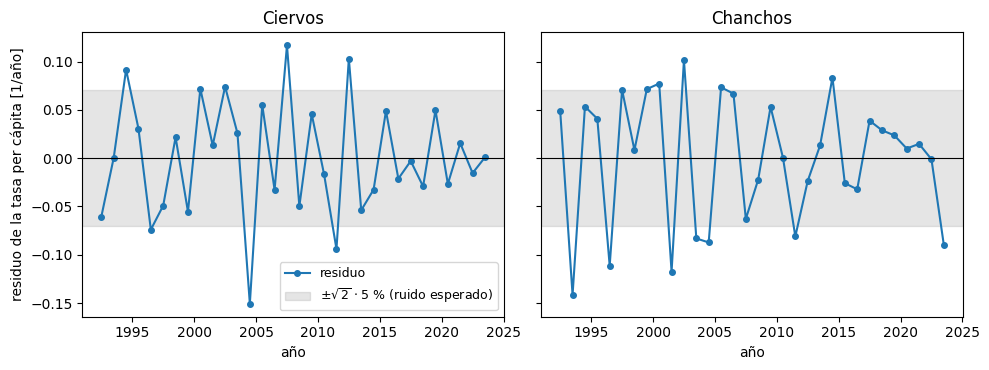

In [17]:
sigma_g = np.sqrt(2) * CV_CENSO
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, res, titulo in [(axs[0], residual_x1, "Ciervos"), (axs[1], residual_y1, "Chanchos")]:
    ax.plot(tk_plus_half_dt1, res, 'o-', ms=4, label="residuo")
    ax.axhline(0, color='k', lw=0.8)
    ax.axhspan(-sigma_g, sigma_g, color='gray', alpha=0.2,
               label=r"$\pm\sqrt{2}\,\cdot$5 % (ruido esperado)")
    ax.set_xlabel("año")
    ax.set_title(titulo)
axs[0].set_ylabel("residuo de la tasa per cápita [1/año]")
axs[0].legend(fontsize=9, loc="lower right")
fig.tight_layout()
guardar(fig, "residuos.png")
plt.show()


#### **1.4**

In [18]:
#Separate between train and test
mask_train = t <= 2012
X_train, Y_train, T_train = x[mask_train], y[mask_train], t[mask_train]

mask_test = t > 2012
X_test, Y_test, T_test = x[mask_test], y[mask_test], t[mask_test]

In [19]:
#Adjust just using the train set
gx_train, gy_train, xk_plus_half_train, yk_plus_half_train, tk_plus_half_train = numerical_derivate(X_train, Y_train, T_train)
theta_x_train, theta_y_train, residual_x_train, residual_y_train = solve(gx_train, gy_train, xk_plus_half_train, yk_plus_half_train)

a1_train, b11_train, b12_train = theta_x_train
a2_train, b21_train, b22_train = theta_y_train
print("Parámetros ajustados con datos 1992–2012:")
print(f"  ciervos  (a1, b11, b12) = {theta_x_train}")
print(f"  chanchos (a2, b21, b22) = {theta_y_train}")


Parámetros ajustados con datos 1992–2012:
  ciervos  (a1, b11, b12) = [4.48010583e-01 2.10865802e-04 4.01531574e-04]
  chanchos (a2, b21, b22) = [6.50833131e-01 2.27243824e-04 7.34649912e-04]


In [20]:
# x= x(a1−b11 x−b12 y),
# y= y(a2−b21 x−b22 y)

def lotka_volterra(tm, z, a1, b11, b12, a2, b21, b22):
    x, y = z
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y)
    return np.array([dxdt, dydt])

In [21]:
index_year_2012 = np.where(t == 2012)[0][0]
# Initial conditions for the ODE solver
z0 = [x[index_year_2012], y[index_year_2012]]

solution = solve_ivp(lotka_volterra, [2012, 2024], z0,
                     args = (a1_train, b11_train, b12_train, a2_train, b21_train, b22_train),
                     dense_output = True, rtol = RTOL, atol = ATOL)

# Evaluate the solution at the test time points
prediction = solution.sol(T_test)
pred_x, pred_y = prediction[0], prediction[1]


In [22]:
# Relative mean error
error_x = np.abs((pred_x - X_test) / X_test)
error_y = np.abs((pred_y - Y_test) / Y_test)

print(f"Error relativo medio, predicción de ciervos 2013–2024: {100*np.mean(error_x):.1f} %")
print(f"Error relativo medio, predicción de chanchos 2013–2024: {100*np.mean(error_y):.1f} %")

Error relativo medio, predicción de ciervos 2013–2024: 3.2 %
Error relativo medio, predicción de chanchos 2013–2024: 3.9 %


### **Ejercicio 2**


### Equilibrio interior: cálculo de $x^*$ e $y^*$

Para el equilibrio interior se piden dos condiciones: $\dot x=0$ y $\dot y=0$ con $x, y \neq 0$. Dividiendo cada ecuación de (1) por $x$ e $y$ respectivamente, se obtiene el siguiente sistema lineal de 2×2:

$$b_{11}x + b_{12}y = a_1 \qquad \text{(I)}$$
$$b_{21}x + b_{22}y = a_2 \qquad \text{(II)}$$

**Despejando $x^*$ (eliminando $y$):**

Multiplicando (I) por $b_{22}$ y (II) por $b_{12}$, los términos en $y$ quedan iguales:

$$b_{22}\cdot\text{(I)}:\quad b_{11}b_{22}\,x + b_{12}b_{22}\,y = a_1 b_{22}$$
$$b_{12}\cdot\text{(II)}:\quad b_{21}b_{12}\,x + b_{22}b_{12}\,y = a_2 b_{12}$$

Restando ambas ecuaciones, el término en $y$ se cancela:

$$(b_{11}b_{22}-b_{12}b_{21})\,x = a_1 b_{22} - a_2 b_{12}$$

Definiendo $\det = b_{11}b_{22}-b_{12}b_{21}$:

$$x^* = \frac{a_1 b_{22} - a_2 b_{12}}{\det}$$

**Despejando $y^*$ (eliminando $x$):**

Multiplicando (I) por $b_{21}$ y (II) por $b_{11}$, los términos en $x$ quedan iguales:

$$b_{21}\cdot\text{(I)}:\quad b_{11}b_{21}\,x + b_{12}b_{21}\,y = a_1 b_{21}$$
$$b_{11}\cdot\text{(II)}:\quad b_{11}b_{21}\,x + b_{11}b_{22}\,y = a_2 b_{11}$$

Restando, el término en $x$ se cancela:

$$(b_{11}b_{22}-b_{12}b_{21})\,y = a_2 b_{11} - a_1 b_{21}$$

$$y^* = \frac{a_2 b_{11} - a_1 b_{21}}{\det}$$

El mismo $\det$ aparece en ambas expresiones porque es el determinante de la matriz de
coeficientes $\begin{pmatrix}b_{11}&b_{12}\\b_{21}&b_{22}\end{pmatrix}$; equivale a aplicar
la regla de Cramer al sistema (I)-(II).


In [23]:
eq1 = (0,0)
eq2 = (K1, 0)
eq3 = (0, K2)

# Internal 
det = b11 * b22 - b12 * b21
x_star = (a1 * b22 - a2 * b12) / det
y_star = (a2 * b11 - a1 * b21) / det
eq4 = (x_star, y_star)

equilibriums = pd.DataFrame({
    "Equilibrio": ["(0,0)", "(K1,0)", "(0,K2)", "interior (x*,y*)"],
    "x [individuos]": [0, K1, 0, x_star],
    "y [individuos]": [0, 0, K2, y_star],
})

display(equilibriums.round(1))



,Equilibrio,x [individuos],y [individuos]
0,"(0,0)",0.0,0.0
1,"(K1,0)",1913.9,0.0
2,"(0,K2)",0.0,908.8
3,"interior (x*,y*)",1010.2,541.7


##### **Estabilidad de los equilibrios**

Se linealiza el sistema en cada equilibrio y se clasifica según la traza, el determinante y los autovalores del jacobiano.


In [24]:
def jacobiano(xe, ye):
    return np.array([[a1 - 2*b11*xe - b12*ye, -b12*xe],
                     [-b21*ye,                 a2 - b21*xe - 2*b22*ye]])

def clasificar(J):
    tr, dt_ = np.trace(J), np.linalg.det(J)
    if dt_ < 0:
        return "silla"
    tipo = "nodo" if tr**2 - 4*dt_ >= 0 else "foco"
    return f"{tipo} {'estable' if tr < 0 else 'inestable'}"

equilibrios = {"(0,0)": (0, 0), "(K1,0)": (K1, 0), "(0,K2)": (0, K2), "(x*,y*)": (x_star, y_star)}
filas = []
for nombre, (xe, ye) in equilibrios.items():
    J = jacobiano(xe, ye)
    lam = np.linalg.eigvals(J)
    filas.append([nombre, xe, ye, np.trace(J), np.linalg.det(J), lam[0], lam[1], clasificar(J)])
tabla_eq = pd.DataFrame(filas, columns=["equilibrio", "x [ind]", "y [ind]", "traza [1/año]",
                                        "det [1/año²]", "λ1 [1/año]", "λ2 [1/año]", "tipo"])
display(tabla_eq.round(4))

lam_int = np.linalg.eigvals(jacobiano(x_star, y_star))
print(f"Constantes de tiempo del equilibrio interior: {np.sort(-1/lam_int).round(1)} años")
print(f"Coexistencia: K1 = {K1:.0f} > alpha12*K2 = {alpha12*K2:.0f}  y  "
      f"K2 = {K2:.0f} > alpha21*K1 = {alpha21*K1:.0f}")


,equilibrio,x [ind],y [ind],traza [1/año],det [1/año²],λ1 [1/año],λ2 [1/año],tipo
0,"(0,0)",0.0000,0.0000,1.0880,0.2871,0.4503,0.6377,nodo inestable
1,"(K1,0)",1913.8922,0.0000,-0.3007,-0.0674,-0.4503,0.1496,silla
2,"(0,K2)",0.0000,908.8166,-0.5441,-0.0597,-0.6377,0.0936,silla
3,"(x*,y*)",1010.2081,541.6639,-0.6177,0.0356,-0.0642,-0.5535,nodo estable


Constantes de tiempo del equilibrio interior: [ 1.8 15.6] años
Coexistencia: K1 = 1914 > alpha12*K2 = 1516  y  K2 = 909 > alpha21*K1 = 696


##### **¿El sistema ya alcanzó el equilibrio en 2024?**


In [25]:
index_2024 = np.where(t == 2024)[0][0]
z0_24 = [x[index_2024], y[index_2024]]

In [26]:
solution_2060 = solve_ivp(lotka_volterra, [2024, 2060], z0_24, args = (a1, b11, b12, a2, b21, b22),
                          dense_output = True, rtol = RTOL, atol = ATOL)

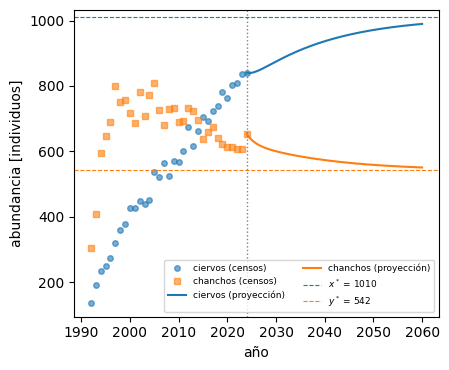

In [27]:
t_linspace = np.linspace(2024, 2060, 361)
trajectory = solution_2060.sol(t_linspace)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.plot(t, x, 'o', color='C0', ms=4, alpha=0.6, label="ciervos (censos)")
ax.plot(t, y, 's', color='C1', ms=4, alpha=0.6, label="chanchos (censos)")
ax.plot(t_linspace, trajectory[0], color='C0', label="ciervos (proyección)")
ax.plot(t_linspace, trajectory[1], color='C1', label="chanchos (proyección)")
ax.axhline(x_star, ls='--', color='C0', lw=0.8, label=f"$x^*$ = {x_star:.0f}")
ax.axhline(y_star, ls='--', color='C1', lw=0.8, label=f"$y^*$ = {y_star:.0f}")
ax.axvline(2024, ls=':', color='gray', lw=1)
ax.set_xlabel("año")
ax.set_ylabel("abundancia [individuos]")
ax.legend(fontsize=6.5, ncol=2)
fig.tight_layout()
guardar(fig, "proyeccion.png")
plt.show()


In [28]:
estado_2060 = solution_2060.sol(2060)
print(f"Estado observado en 2024:  x = {z0_24[0]:.0f}, y = {z0_24[1]:.0f}")
print(f"Estado proyectado en 2060: x = {estado_2060[0]:.0f}, y = {estado_2060[1]:.0f}")
print(f"Equilibrio interior:       x* = {x_star:.0f}, y* = {y_star:.0f}")

dist_2024 = np.hypot(z0_24[0] - x_star, z0_24[1] - y_star)
print(f"\nDistancia al equilibrio en 2024: {dist_2024:.1f} individuos")

Estado observado en 2024:  x = 840, y = 653
Estado proyectado en 2060: x = 989, y = 551
Equilibrio interior:       x* = 1010, y* = 542

Distancia al equilibrio en 2024: 203.4 individuos


In [29]:
t_fino = np.linspace(2024, 2060, 3601)
tray = solution_2060.sol(t_fino)
dist_rel = np.hypot((tray[0] - x_star) / x_star, (tray[1] - y_star) / y_star)
t_5 = t_fino[np.argmax(dist_rel < 0.05)]
print(f"Distancia relativa al equilibrio en 2024: {100*dist_rel[0]:.0f} %")
print(f"Año en que queda a menos del 5 % del equilibrio: {t_5:.0f}")


Distancia relativa al equilibrio en 2024: 27 %
Año en que queda a menos del 5 % del equilibrio: 2050


##### **Diagrama de fases**

Nulclinas, campo de direcciones, los cuatro equilibrios según su tipo, la trayectoria de los censos 1992–2024 y la proyección hasta 2060.


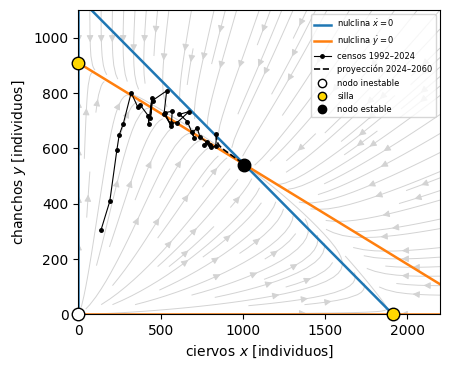

In [30]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
xmax, ymax = 2200, 1100
X, Y = np.meshgrid(np.linspace(1, xmax, 40), np.linspace(1, ymax, 40))
U, V = lotka_volterra(0, [X, Y], a1, b11, b12, a2, b21, b22)
ax.streamplot(X, Y, U, V, color='lightgray', density=1.1, linewidth=0.7)
xs_ = np.linspace(0, xmax, 200)
ax.plot(xs_, (a1 - b11 * xs_) / b12, color='C0', lw=1.8, label=r"nulclina $\dot x = 0$")
ax.plot(xs_, (a2 - b21 * xs_) / b22, color='C1', lw=1.8, label=r"nulclina $\dot y = 0$")
ax.axvline(0, color='C0', lw=1.8); ax.axhline(0, color='C1', lw=1.8)
ax.plot(x, y, 'k.-', ms=5, lw=0.8, label="censos 1992–2024")
ax.plot(trajectory[0], trajectory[1], 'k--', lw=1.2, label="proyección 2024–2060")
colores = {"(0,0)": "white", "(K1,0)": "gold", "(0,K2)": "gold", "(x*,y*)": "black"}
for nombre, (xe, ye) in equilibrios.items():
    ax.plot(xe, ye, 'o', mfc=colores[nombre], mec='k', ms=9, zorder=5, clip_on=False)
ax.plot([], [], 'o', mfc='white', mec='k', label="nodo inestable")
ax.plot([], [], 'o', mfc='gold', mec='k', label="silla")
ax.plot([], [], 'o', mfc='black', mec='k', label="nodo estable")
ax.set_xlim(0, xmax); ax.set_ylim(0, ymax)
ax.set_xlabel("ciervos $x$ [individuos]")
ax.set_ylabel("chanchos $y$ [individuos]")
ax.legend(fontsize=6, loc="upper right")
fig.tight_layout()
guardar(fig, "fases.png")
plt.show()


#### **Ejercicio 3**

In [31]:
def controlled_lotka_volterra(tm, z, k):
    # x = deer population, y = pigs population
    x, y = z
    u = k * y
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

##### **Simulaciones con extracción proporcional $u = ky$**


In [32]:
k_list = [0, 0.1, 0.2, 0.4]
t_list = np.linspace(0, 40, 401)

results = {}
for k in k_list:
    solution = solve_ivp(controlled_lotka_volterra, [0, 40], z0_24, args = (k, ),
                         dense_output = True, rtol = RTOL, atol = ATOL, t_eval = t_list)
    results[k] = solution


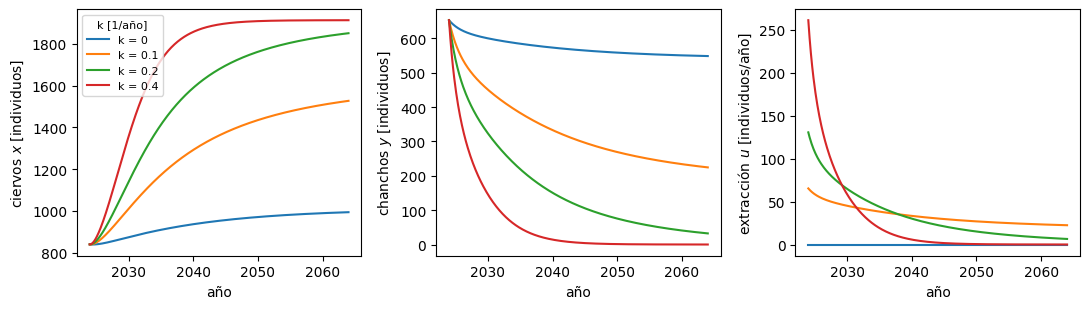

In [33]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for k in k_list:
    sol = results[k]
    axs[0].plot(2024 + sol.t, sol.y[0], label=f"k = {k}")
    axs[1].plot(2024 + sol.t, sol.y[1], label=f"k = {k}")
    axs[2].plot(2024 + sol.t, k * sol.y[1], label=f"k = {k}")
axs[0].set_ylabel("ciervos $x$ [individuos]")
axs[1].set_ylabel("chanchos $y$ [individuos]")
axs[2].set_ylabel("extracción $u$ [individuos/año]")
for a in axs:
    a.set_xlabel("año")
axs[0].legend(title="k [1/año]", fontsize=8, title_fontsize=8)
fig.tight_layout()
guardar(fig, "simulaciones.png")
plt.show()

In [34]:
for k in k_list:
    solution = results[k]
    u_t = k * solution.y[1]

    extracted = np.trapezoid(u_t, solution.t)
    print(f"k = {k} -> animales extraídos en 40 años = {extracted:.0f}")


k = 0 -> animales extraídos en 40 años = 0
k = 0.1 -> animales extraídos en 40 años = 1340
k = 0.2 -> animales extraídos en 40 años = 1336
k = 0.4 -> animales extraídos en 40 años = 1001


In [35]:
# With u = k·y the model is the same with a2 -> a2 - k
k_crit = a2 - b21 * K1
print(f"k crítico = a2 - b21*K1 = {k_crit:.3f} 1/año  (para k >= k_crit los chanchos se extinguen)")

filas = []
for k in k_list:
    if k < k_crit:
        x_eq_k = (a1 * b22 - (a2 - k) * b12) / det
        y_eq_k = ((a2 - k) * b11 - a1 * b21) / det
    else:
        x_eq_k, y_eq_k = K1, 0.0
    x40, y40 = results[k].y[:, -1]
    filas.append([k, x40, y40, x_eq_k, y_eq_k])
tabla_ctrl = pd.DataFrame(filas, columns=["k [1/año]", "x(40) [ind]", "y(40) [ind]",
                                          "x equilibrio [ind]", "y equilibrio [ind]"])
display(tabla_ctrl.round(1))

sol_larga = solve_ivp(controlled_lotka_volterra, [0, 400], z0_24, args=(0.2,), rtol=RTOL, atol=ATOL)
print(f"Chequeo k = 0.2 a 400 años: x = {sol_larga.y[0, -1]:.0f}, y = {sol_larga.y[1, -1]:.2f}")


k crítico = a2 - b21*K1 = 0.150 1/año  (para k >= k_crit los chanchos se extinguen)


,k [1/año],x(40) [ind],y(40) [ind],x equilibrio [ind],y equilibrio [ind]
0,0.0,994.2,548.6,1010.2,541.7
1,0.1,1527.5,224.6,1614.2,179.6
2,0.2,1851.5,32.4,1913.9,0.0
3,0.4,1913.8,0.0,1913.9,0.0


Chequeo k = 0.2 a 400 años: x = 1914, y = 0.00


##### **Saturación**


In [36]:
u_max = 120

In [37]:
def satured_lotka_volterra(tm, z, k):
    x, y = z
    u = min(u_max, k * y)
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

In [38]:
results_saturation = {}
for k in k_list:
    solution = solve_ivp(satured_lotka_volterra, [0, 40], z0_24, args = (k, ),
                         dense_output = True, rtol = RTOL, atol = ATOL, t_eval = t_list)
    results_saturation[k] = solution


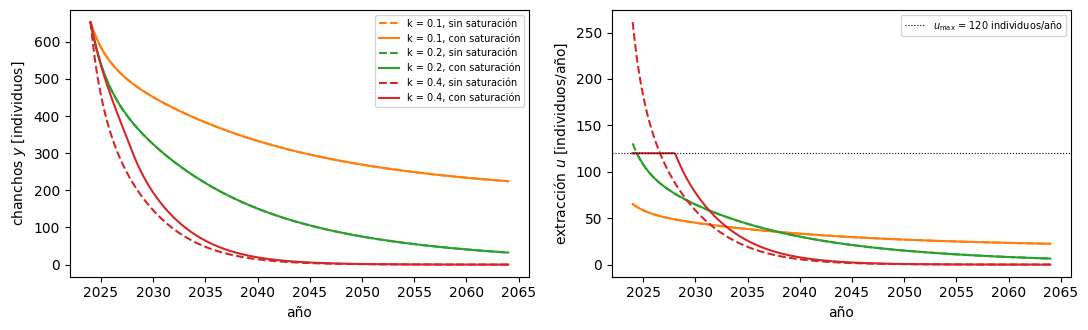

In [39]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for i, k in enumerate([0.1, 0.2, 0.4]):
    c = f"C{i+1}"
    sol_sin, sol_con = results[k], results_saturation[k]
    axs[0].plot(2024 + sol_sin.t, sol_sin.y[1], '--', color=c, label=f"k = {k}, sin saturación")
    axs[0].plot(2024 + sol_con.t, sol_con.y[1], '-', color=c, label=f"k = {k}, con saturación")
    axs[1].plot(2024 + sol_sin.t, k * sol_sin.y[1], '--', color=c)
    axs[1].plot(2024 + sol_con.t, np.minimum(u_max, k * sol_con.y[1]), '-', color=c)
axs[1].axhline(u_max, color='k', lw=0.8, ls=':', label=r"$u_{\max}$ = 120 individuos/año")
axs[0].set_ylabel("chanchos $y$ [individuos]")
axs[1].set_ylabel("extracción $u$ [individuos/año]")
for a in axs:
    a.set_xlabel("año")
axs[0].legend(fontsize=7); axs[1].legend(fontsize=7)
fig.tight_layout()
guardar(fig, "saturacion.png")
plt.show()

In [40]:
for k in [0.1, 0.2, 0.4]:
    sol_no_sat, sol_sat = results[k], results_saturation[k] 
    final_no_sat = sol_no_sat.y[:, -1]
    final_sat = sol_sat.y[:, -1]

    u_sat = np.minimum(u_max, k * sol_sat.y[1])
    total_sat = np.trapezoid(u_sat, sol_sat.t)

    print(f"\nk = {k}:")
    print(f"Estado final SIN saturación -> x = {final_no_sat[0]:.0f}, y = {final_no_sat[1]:.1f}")
    print(f"Estado final CON saturación -> x = {final_sat[0]:.0f}, y = {final_sat[1]:.1f}")
    print(f"Extraídos con saturación = {total_sat:.0f}")



k = 0.1:
Estado final SIN saturación -> x = 1528, y = 224.6
Estado final CON saturación -> x = 1528, y = 224.6
Extraídos con saturación = 1340

k = 0.2:
Estado final SIN saturación -> x = 1851, y = 32.4
Estado final CON saturación -> x = 1851, y = 32.4
Extraídos con saturación = 1336

k = 0.4:
Estado final SIN saturación -> x = 1914, y = 0.0
Estado final CON saturación -> x = 1914, y = 0.0
Extraídos con saturación = 1019


In [41]:
for k in [0.1, 0.2, 0.4]:
    sol = results_saturation[k]
    saturado = k * sol.y[1] >= u_max
    dur = sol.t[saturado].max() if saturado.any() else 0.0
    dif = np.max(np.abs(sol.y[1] - results[k].y[1]))
    print(f"k = {k}: u = u_max durante los primeros {dur:.1f} años; "
          f"máxima diferencia en y(t) con vs sin saturación = {dif:.0f} ind")


k = 0.1: u = u_max durante los primeros 0.0 años; máxima diferencia en y(t) con vs sin saturación = 0 ind
k = 0.2: u = u_max durante los primeros 0.4 años; máxima diferencia en y(t) con vs sin saturación = 2 ind
k = 0.4: u = u_max durante los primeros 4.0 años; máxima diferencia en y(t) con vs sin saturación = 104 ind


##### **Política con umbral**


In [42]:
y_ref = 150

In [43]:
def threshold_lotka_volterra(tm, z, k):
    x, y = z
    u = min(u_max, k * max(0, y - y_ref))
    dxdt = x * (a1 - b11 * x - b12 * y)
    dydt = y * (a2 - b21 * x - b22 * y) - u
    return np.array([dxdt, dydt])

In [44]:
k_umbral = [0.3, 0.5, 1.0, 2.0]
results_threshold_policy = {}
filas = []
for k in k_umbral:
    sol = solve_ivp(threshold_lotka_volterra, [0, 40], z0_24, args = (k, ),
                    dense_output = True, rtol = RTOL, atol = ATOL, t_eval = t_list)
    results_threshold_policy[k] = sol
    y_f = sol.y[1, -1]
    e_ss = y_f - y_ref
    u_t = np.minimum(u_max, k * np.maximum(0, sol.y[1] - y_ref))
    fuera = np.abs(sol.y[1] - y_f) > 0.05 * y_f
    t_est = sol.t[fuera].max() if fuera.any() else 0.0
    filas.append([k, y_f, e_ss, k * e_ss, u_t.max(), t_est, np.trapezoid(u_t, sol.t)])
tabla_umbral = pd.DataFrame(filas, columns=["k [1/año]", "y_f [ind]", "error [ind]",
                                            "u_ss = k·e [ind/año]", "u máx [ind/año]",
                                            "t establecimiento 5% [años]", "extraídos [ind]"])
display(tabla_umbral.round(1))


,k [1/año],y_f [ind],error [ind],u_ss = k·e [ind/año],u máx [ind/año],t establecimiento 5% [años],extraídos [ind]
0,0.3,215.0,65.0,19.5,120.0,20.5,1401.1
1,0.5,186.6,36.6,18.3,120.0,14.6,1386.1
2,1.0,167.3,17.3,17.3,120.0,9.9,1350.0
3,2.0,158.4,8.4,16.8,120.0,7.1,1330.9


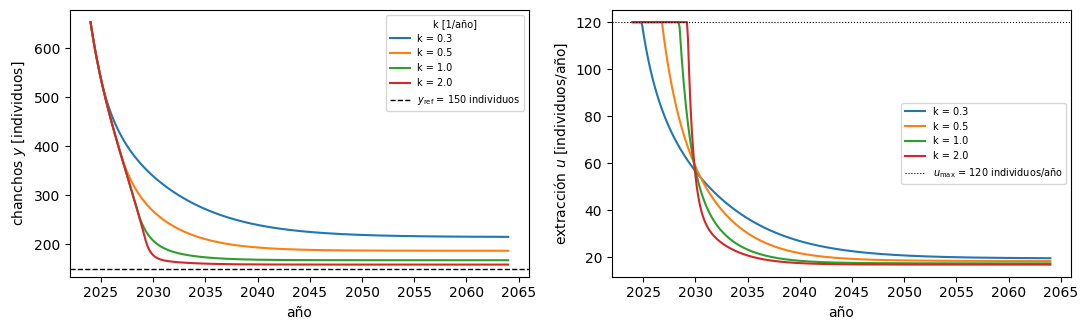

In [45]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for k in k_umbral:
    sol = results_threshold_policy[k]
    axs[0].plot(2024 + sol.t, sol.y[1], label=f"k = {k}")
    axs[1].plot(2024 + sol.t, np.minimum(u_max, k * np.maximum(0, sol.y[1] - y_ref)), label=f"k = {k}")
axs[0].axhline(y_ref, color='k', ls='--', lw=1, label=r"$y_{\mathrm{ref}}$ = 150 individuos")
axs[1].axhline(u_max, color='k', ls=':', lw=0.8, label=r"$u_{\max}$ = 120 individuos/año")
axs[0].set_ylabel("chanchos $y$ [individuos]")
axs[1].set_ylabel("extracción $u$ [individuos/año]")
for a in axs:
    a.set_xlabel("año")
axs[0].legend(title="k [1/año]", fontsize=7, title_fontsize=7); axs[1].legend(fontsize=7)
fig.tight_layout()
guardar(fig, "umbral.png")
plt.show()

In [46]:
x_no_control = results[0].y[0, -1]
print(f'Ciervos sin control (40 años) = {x_no_control:.0f}')

print('\n--- 3.1 proporcional ---')
for k in k_list:
    x_f = results[k].y[0, -1]
    print(f'k = {k} -> ciervos = {x_f:.0f} ({100 * (x_f / x_no_control - 1):+.0f}% vs sin control)')

print('\n--- 3.2 con saturación (u_max = 120) ---')
for k in k_list:
    x_f = results_saturation[k].y[0, -1]
    print(f'k = {k} -> ciervos = {x_f:.0f} ({100 * (x_f / x_no_control - 1):+.0f}% vs sin control)')

print('\n--- 3.3 umbral (y_ref = 150) ---')
for k in k_umbral:
    x_f = results_threshold_policy[k].y[0, -1]
    print(f'k = {k} -> ciervos = {x_f:.0f} ({100 * (x_f / x_no_control - 1):+.0f}% vs sin control)')


Ciervos sin control (40 años) = 994

--- 3.1 proporcional ---
k = 0 -> ciervos = 994 (+0% vs sin control)
k = 0.1 -> ciervos = 1528 (+54% vs sin control)
k = 0.2 -> ciervos = 1851 (+86% vs sin control)
k = 0.4 -> ciervos = 1914 (+92% vs sin control)

--- 3.2 con saturación (u_max = 120) ---
k = 0 -> ciervos = 994 (+0% vs sin control)
k = 0.1 -> ciervos = 1528 (+54% vs sin control)
k = 0.2 -> ciervos = 1851 (+86% vs sin control)
k = 0.4 -> ciervos = 1914 (+92% vs sin control)

--- 3.3 umbral (y_ref = 150) ---
k = 0.3 -> ciervos = 1555 (+56% vs sin control)
k = 0.5 -> ciervos = 1603 (+61% vs sin control)
k = 1.0 -> ciervos = 1635 (+64% vs sin control)
k = 2.0 -> ciervos = 1650 (+66% vs sin control)
